In [1]:
import math
import torch
import torch.nn as nn
from lab05_starter import train_recall, train_order, reference_attention, ReferenceMHA

In [5]:
SEEDS = (0, 1, 2)

# Part 1: Attention

In [2]:
def scaled_dot_product_attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])

    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))

    weights = torch.softmax(scores, dim=-1)

    assert torch.allclose(
        weights.sum(dim=-1),
        torch.ones_like(weights.sum(dim=-1)),
        atol=1e-6
    )

    if mask is not None:
        assert torch.all(weights.masked_select(~mask) == 0)

    output = weights @ v

    return output, weights

In [ ]:
for seed in SEEDS:
    torch.manual_seed(seed)

    q = torch.randn(2, 4, 8)
    k = torch.randn(2, 4, 8)
    v = torch.randn(2, 4, 8)

    # Without mask
    my_output, _ = scaled_dot_product_attention(q, k, v)
    ref_output, _ = reference_attention(q, k, v)

    print(f"Seed {seed} without mask:",
          torch.allclose(my_output, ref_output, atol=1e-5))

    # With causal mask
    mask = torch.tril(torch.ones(4, 4, dtype=torch.bool))

    my_output, _ = scaled_dot_product_attention(q, k, v, mask)
    ref_output, _ = reference_attention(q, k, v, mask)

    print(f"Seed {seed} with mask:", torch.allclose(my_output, ref_output, atol=1e-5))

Seed 0 without mask: True
Seed 0 with mask: True
Seed 1 without mask: True
Seed 1 with mask: True
Seed 2 without mask: True
Seed 2 with mask: True


In [4]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()

        assert d_model % n_heads == 0

        self.n_heads = n_heads
        self.head_dim = d_model // n_heads

        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x, context=None, mask=None):
        if context is None:
            context = x

        batch_size, q_len, _ = x.shape
        k_len = context.shape[1]

        q = self.q_proj(x)
        k = self.k_proj(context)
        v = self.v_proj(context)

        q = q.reshape(batch_size, q_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.reshape(batch_size, k_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.reshape(batch_size, k_len, self.n_heads, self.head_dim).transpose(1, 2)

        output, _ = scaled_dot_product_attention(q, k, v, mask)

        output = output.transpose(1, 2).reshape(batch_size, q_len, -1)

        return self.out_proj(output)

In [6]:
for seed in SEEDS:
    torch.manual_seed(seed)

    my_mha = MultiHeadAttention(32, 4)
    ref_mha = ReferenceMHA(32, 4)

    # Copy PyTorch's weights into our model
    with torch.no_grad():
        q_weight, k_weight, v_weight = ref_mha.mha.in_proj_weight.chunk(3)
        q_bias, k_bias, v_bias = ref_mha.mha.in_proj_bias.chunk(3)

        for proj, weight, bias in zip(
            (my_mha.q_proj, my_mha.k_proj, my_mha.v_proj),
            (q_weight, k_weight, v_weight),
            (q_bias, k_bias, v_bias)
        ):
            proj.weight.copy_(weight)
            proj.bias.copy_(bias)

        my_mha.out_proj.weight.copy_(ref_mha.mha.out_proj.weight)
        my_mha.out_proj.bias.copy_(ref_mha.mha.out_proj.bias)

    x = torch.randn(2, 4, 32)
    context = torch.randn(2, 6, 32)
    mask = torch.tril(torch.ones(4, 4, dtype=torch.bool))

    # Self-attention
    print(f"Seed {seed} self-attention:",
          torch.allclose(my_mha(x), ref_mha(x), atol=1e-5))

    # Causal self-attention
    print(f"Seed {seed} causal attention:",
          torch.allclose(my_mha(x, mask=mask),
                         ref_mha(x, mask=mask), atol=1e-5))

    # Cross-attention (different sequence lengths)
    print(f"Seed {seed} cross-attention:",
          torch.allclose(my_mha(x, context),
                         ref_mha(x, context), atol=1e-5))

Seed 0 self-attention: True
Seed 0 causal attention: True
Seed 0 cross-attention: True
Seed 1 self-attention: True
Seed 1 causal attention: True
Seed 1 cross-attention: True
Seed 2 self-attention: True
Seed 2 causal attention: True
Seed 2 cross-attention: True


In [7]:
for heads in (1, 2, 4, 8):
    model = MultiHeadAttention(32, heads)
    count = sum(p.numel() for p in model.parameters())
    print(f"{heads} heads: {count} parameters")

1 heads: 4224 parameters
2 heads: 4224 parameters
4 heads: 4224 parameters
8 heads: 4224 parameters


In [8]:
torch.manual_seed(0)

model = MultiHeadAttention(32, 4)
x = torch.randn(2, 6, 32)

shuffle = torch.randperm(6)

original = model(x)
shuffled = model(x[:, shuffle])

print("Shuffle test:", torch.allclose(shuffled, original[:, shuffle], atol=1e-5))

Shuffle test: True


# Part 2: Recall

In [9]:
for length in (30, 100, 400):
    for seed in (0, 1, 2):
        attention_acc, weight0 = train_recall(
            "attention",
            seq_len=length,
            seed=seed,
            attention_fn=scaled_dot_product_attention
        )

        lstm_acc, _ = train_recall(
            "lstm",
            seq_len=length,
            seed=seed
        )

        print(f"Length {length}, Seed {seed}")
        print(f"  Attention: {attention_acc:.3f}, Weight on step 0: {weight0:.3f}")
        print(f"  LSTM: {lstm_acc:.3f}")

Length 30, Seed 0
  Attention: 1.000, Weight on step 0: 0.730
  LSTM: 1.000
Length 30, Seed 1
  Attention: 1.000, Weight on step 0: 0.742
  LSTM: 1.000
Length 30, Seed 2
  Attention: 1.000, Weight on step 0: 0.674
  LSTM: 1.000
Length 100, Seed 0
  Attention: 1.000, Weight on step 0: 0.738
  LSTM: 0.252
Length 100, Seed 1
  Attention: 1.000, Weight on step 0: 0.746
  LSTM: 1.000
Length 100, Seed 2
  Attention: 1.000, Weight on step 0: 0.658
  LSTM: 0.499
Length 400, Seed 0
  Attention: 1.000, Weight on step 0: 0.741
  LSTM: 0.245
Length 400, Seed 1
  Attention: 1.000, Weight on step 0: 0.746
  LSTM: 0.244
Length 400, Seed 2
  Attention: 1.000, Weight on step 0: 0.663
  LSTM: 0.245


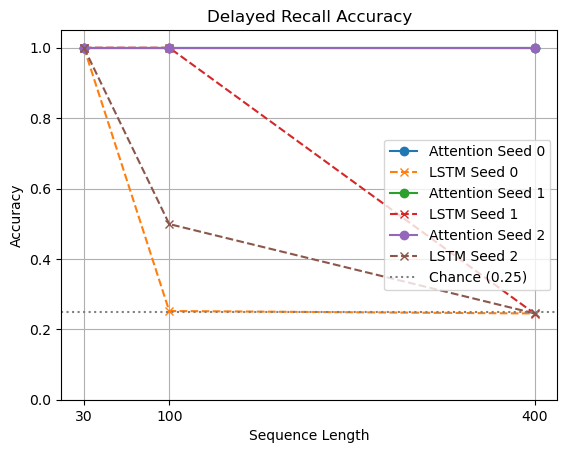

In [11]:
import matplotlib.pyplot as plt

lengths = [30, 100, 400]

attention = [
    [1.000, 1.000, 1.000],
    [1.000, 1.000, 1.000],
    [1.000, 1.000, 1.000]
]
lstm = [
    [1.000, 0.252, 0.245],
    [1.000, 1.000, 0.244],
    [1.000, 0.499, 0.245]
]

for seed in (0, 1, 2):
    plt.plot(lengths, attention[seed], marker="o",
             label=f"Attention Seed {seed}")

    plt.plot(lengths, lstm[seed], marker="x",
             linestyle="--", label=f"LSTM Seed {seed}")

plt.axhline(0.25, color="gray", linestyle=":",
            label="Chance (0.25)")

plt.xlabel("Sequence Length")
plt.ylabel("Accuracy")
plt.title("Delayed Recall Accuracy")
plt.xticks(lengths)
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.savefig("recall.png", dpi=300, bbox_inches="tight")
plt.show()

# Part 3: Positions on the Order Task

In [12]:
for pos in ("none", "learned", "sinusoidal"):
    for seed in (0, 1, 2):
        accs = train_order(
            pos,
            seed=seed,
            train_len=16,
            test_lens=(16, 32),
            attention_cls=MultiHeadAttention
        )

        print(f"{pos}, Seed {seed}")
        print(f"  Length 16: {accs[0]:.3f}")
        print(f"  Length 32: {accs[1]:.3f}")

none, Seed 0
  Length 16: 0.552
  Length 32: 0.503
none, Seed 1
  Length 16: 0.523
  Length 32: 0.484
none, Seed 2
  Length 16: 0.447
  Length 32: 0.498
learned, Seed 0
  Length 16: 1.000
  Length 32: 0.620
learned, Seed 1
  Length 16: 1.000
  Length 32: 0.601
learned, Seed 2
  Length 16: 1.000
  Length 32: 0.623
sinusoidal, Seed 0
  Length 16: 1.000
  Length 32: 0.643
sinusoidal, Seed 1
  Length 16: 1.000
  Length 32: 0.664
sinusoidal, Seed 2
  Length 16: 1.000
  Length 32: 0.750


In [13]:
for pos in ("none", "learned", "sinusoidal"):
    for seed in (0, 1, 2):
        accs = train_order(
            pos,
            seed=seed,
            mixed_lens=(8, 16, 24),
            test_lens=(16, 32, 48),
            attention_cls=MultiHeadAttention
        )

        print(f"{pos}, Seed {seed}")
        print(f"  Length 16: {accs[0]:.3f}")
        print(f"  Length 32: {accs[1]:.3f}")
        print(f"  Length 48: {accs[2]:.3f}")

none, Seed 0
  Length 16: 0.494
  Length 32: 0.516
  Length 48: 0.493
none, Seed 1
  Length 16: 0.512
  Length 32: 0.479
  Length 48: 0.508
none, Seed 2
  Length 16: 0.539
  Length 32: 0.507
  Length 48: 0.481
learned, Seed 0
  Length 16: 0.975
  Length 32: 0.703
  Length 48: 0.558
learned, Seed 1
  Length 16: 1.000
  Length 32: 0.718
  Length 48: 0.549
learned, Seed 2
  Length 16: 1.000
  Length 32: 0.706
  Length 48: 0.543
sinusoidal, Seed 0
  Length 16: 1.000
  Length 32: 0.893
  Length 48: 0.615
sinusoidal, Seed 1
  Length 16: 1.000
  Length 32: 0.901
  Length 48: 0.580
sinusoidal, Seed 2
  Length 16: 1.000
  Length 32: 0.929
  Length 48: 0.750
